In [45]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
%% matplotlib inline
np.__version__

UsageError: Line magic function `%%` not found.


In [32]:
list1 = [9, 5, 3, 6, 11, 5, 17, 12, 4, 2]
list1

[9, 5, 3, 6, 11, 5, 17, 12, 4, 2]

In [20]:
mean=np.mean(list1)
median = np.median(list1)
#finding mode with numpy is two step process  
datapoints,index=  np.unique(list1,return_counts=True)
print('datapoints',datapoints)
print('index',index)
mode =datapoints[np.argmax(index)]
std = np.std(list1)
variance = np.var(list1)
mad1=np.mean(np.abs(list1-np.mean(list1)))
print(list1)
print(f'mode of the list is {mode}')
print(f'mean of the list is {mean}')
print(f'median of the list is {median}')
print(f'standard deviation of the list is {std}')
print(f'variance of the list is {variance}')
print(f'mad of the list is {mad1}')
print('---'* 20)

datapoints [-5.4 -4.4 -3.4 -2.4 -1.4  1.6  3.6  4.6  9.6]
index [1 1 1 2 1 1 1 1 1]
[ 1.6 -2.4 -4.4 -1.4  3.6 -2.4  9.6  4.6 -3.4 -5.4]
mode of the list is -2.4000000000000004
mean of the list is -3.552713678800501e-16
median of the list is -1.9000000000000004
standard deviation of the list is 4.498888751680798
variance of the list is 20.240000000000002
mad of the list is 3.88
------------------------------------------------------------


# finding the IQR

In [33]:
# Q1 = np.quatile(list1,0.25)
# Q3 = np.qurantile(list1,0.75)
Q1 = np.percentile(list1,25)
Q3 = np.percentile(list1,75)
print("The Q1 value is: ",Q1)
print("The Q3 value is: ",Q3)
IQR = Q3 - Q1
print("The IQR value is: ",IQR)
lower_bound =Q1 - 1.5*IQR
upper_bound = Q3 + 1.5 * IQR
print("The lower bound is: ",lower_bound)
print("The upper bound is: ",upper_bound)

The Q1 value is:  4.25
The Q3 value is:  10.5
The IQR value is:  6.25
The lower bound is:  -5.125
The upper bound is:  19.875


In [28]:
outliers =  [x for x in list1 if x < lower_bound or x > upper_bound]
print(f'outliers: {outliers}')

outliers: []


In [35]:
list2 = [70, 75, 80, 40, 85, 90, 130, 95, 100]
mean = np.mean(list2)
median = np.median(list2)
datapoints,index =np.unique(list2,return_counts=True)
mode =datapoints[np.argmax(index)]
std = np.std(list2)
variance =np.var(list2)
mad= np.mean(np.abs(list2-np.mean(list2)))
print(f'mean={mean},median={median},mode={mode},std={std},variance={variance},mad={mad}')

mean=85.0,median=85.0,mode=40,std=22.973414586817036,variance=527.7777777777778,mad=16.666666666666668


In [36]:
Q1=np.percentile(list2,25)
Q3=np.percentile(list2,75)
IQR=Q3-Q1
lower_bound= Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print(f"Lower Bound: {lower_bound}")
print(f"Upper Bound: {upper_bound}")
outliers =  [ x for x in list2 if x< lower_bound or x > upper_bound ]
print(f"Outliers: {outliers}")

Lower Bound: 45.0
Upper Bound: 125.0
Outliers: [40, 130]


In [39]:
print (list2)
print(outliers)
# create new list exluding outliers
list3=[x for x in list2 if x not in outliers]
print(list3)

[70, 75, 80, 40, 85, 90, 130, 95, 100]
[40, 130]
[70, 75, 80, 85, 90, 95, 100]


In [43]:
mode = stats.mode(list2)
print(f"Mode: {mode[0]}")

Mode: 40


In [44]:
skewness =stats.skew(list1)
kurtosis = stats.kurtosis(list1)
#skewness  < 0 left tail negative skew, skewness > 0 right tail positive skew skewness = 0 normal distribution
print(f'Skewness: {skewness}') # positive skew mean tail to towards right
#kurtosis < 0 light tail ,kurtosis > 0 heavy tail kurotosis=0 means normal
print(f'Kurtosis: {kurtosis}')  # negative kurtosis

Skewness: 0.7912362343115273
Kurtosis: -0.4259791591807409


In [50]:
#plotting 
list1 =np.array([70, 75, 80, 40, 85, 90, 130, 95, 100])
mean=np.mean(list1)
median = np.median(list1)
mode=stats.mode(list1)[0]
std=np.std(list1,ddof=0) #delta degrees of freedom =0 means population std N
var=np.var(list1)
skew=stats.skew(list1)
kurt=stats.kurtosis(list1)


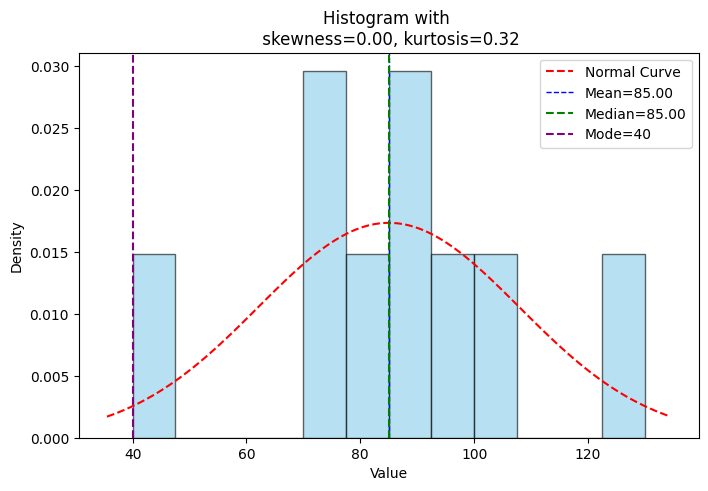

In [51]:
# Plotting a histogram
plt.figure(figsize=(8,5))
plt.hist(list1,bins=12,density=True,alpha=0.6,edgecolor='black',color='skyblue')

#overlay normal curve withsame mean and std
xmin,xmax =plt.xlim()
x_axis = np.linspace(xmin,xmax,100)
plt.plot(x_axis,stats.norm.pdf(x_axis,mean,std),'r--',label='Normal Curve')

#Mean and Median Markers
plt.axvline(np.mean(list1),color='b',linestyle='dashed',linewidth=1,label=f"Mean={mean:.2f}")  #AXvline for vertical line
plt.axvline(np.median(list1),color='green',linestyle='dashed',linewidth=1.5,label=f"Median={median:.2f}")
plt.axvline(stats.mode(list1)[0],color='purple',linestyle='dashed',linewidth=1.5,label=f"Mode={mode}")  #AXvline for vertical line

#Title and axis labels
plt.title(f"Histogram with \n skewness={skew:.2f}, kurtosis={kurt:.2f}",fontsize=12)
plt.xlabel("Value")
plt.ylabel("Density")
plt.legend()
plt.show()